# Langendorff infarct size — figures (PDF) from the spreadsheet

Upload **either** the original `Infarct_Size.xlsx` (sheets *Rhein pre and post* / *Diacerein Gavage*, one block per heart) **or** the clean `Infarct_size_analysis.xlsx` (uses its *Hearts* sheet). The notebook detects which one it got.

**Excluded hearts.** Two high-dose diacerein blocks are dropped in cell 3 (`EXCLUDE`):

* `Diacerein - 5 b (high dose)` — the source file carries two blocks both labelled `Diacerein - 5 (high dose)`; the second holds entirely different pixel data and could not be traced to an animal.
* `Diacerein - 8 (high dose)` — only four usable slices, and on slice 5 the risk tracing covers the whole left ventricle (non-risk area −162 px, AAR 100.1%), which is not physically possible.

Both are consistent with the TTC image archive (`1J-oral diacerein/`), which holds seven high-dose hearts. Set `EXCLUDE = set()` to reproduce the earlier nine-heart analysis.

Outputs: `infarct_rhein.pdf` and `infarct_diacerein.pdf` (4.6 × 5.0 cm, vector, editable text, 8 pt type per AHA figure guidelines), PNG previews, `hearts.csv`, a QC table, and a stats printout. Run all cells; the file picker appears in cell 2.

In [1]:
#@title 1 · Setup
import re, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from itertools import combinations

FS = 8   # AHA: type inside a figure must be 8–10 pt. Applies to axes, ticks and bracket labels.
plt.rcParams.update({'pdf.fonttype': 42, 'ps.fonttype': 42, 'font.family': 'DejaVu Sans', 'font.size': FS,
                     'axes.labelsize': FS, 'xtick.labelsize': FS, 'ytick.labelsize': FS})
print('ok')

ok


In [2]:
#@title 2 · Upload spreadsheet (original or clean workbook)
try:
    from google.colab import files
    up = files.upload(); FILE = next(iter(up))
except ImportError:
    FILE = 'Infarct_Size.xlsx'   # local fallback
import openpyxl
wb = openpyxl.load_workbook(FILE, data_only=True)
print('file:', FILE, '| sheets:', wb.sheetnames)

Saving Infarct_size_analysis.xlsx to Infarct_size_analysis.xlsx
file: Infarct_size_analysis.xlsx | sheets: ['README', 'Slices', 'Hearts', 'Stats', 'Long format', 'Figures']


In [3]:
#@title 3 · Read heart-level infarct values
EXP = {'Rhein pre and post': 'Rhein (Langendorff perfusion)', 'Diacerein Gavage': 'Diacerein (oral gavage)'}
GRP = {'Control': 'Control', 'Rhein treatment at the onset of reperfusion (20uM)': 'Reperfusion', 'Rhein pre ischemia': 'Pre-ischemia',
       'Gavagem low dose': 'Low dose', 'Diacerein high dose': 'High dose'}
HEART_RE = r'^(Control_\d|Rhein_\d|Diacerein - \d)'

# Hearts removed from the analysis. See the notes at the top of this notebook.
# Set EXCLUDE = set() to reproduce the earlier analysis with all nine high-dose blocks.
EXCLUDE = {'Diacerein - 5 b (high dose)', 'Diacerein - 8 (high dose)'}

def parse_original(wb):
    """Walk each sheet: group titles and heart titles in column A, 'Total Area' header, then one row per slice.
    Areas: B total, S halo, G risk, O infarct. Slices with 'n/a' are skipped. Duplicate heart labels get a 'b' suffix."""
    rows = []
    for ws in wb:
        if ws.title not in EXP: continue
        r, group, heart, seen = 1, None, None, set()
        while r <= ws.max_row:
            a = ws.cell(row=r, column=1).value
            if isinstance(a, str) and ws.cell(row=r, column=2).value is None and a.strip() != 'Total Area':
                s = a.strip()
                if re.match(HEART_RE, s):
                    heart = s if s not in seen else s.replace('(', 'b (')
                    seen.add(s)
                else:
                    group = s
            if a == 'Total Area':
                rr = r + 1
                while ws.cell(row=rr, column=4).value != 'Total %' and rr < r + 12:
                    g = lambda c: ws.cell(row=rr, column=c).value
                    if isinstance(g(1), (int, float)) or isinstance(g(18), (int, float)):
                        rows.append(dict(exp=EXP[ws.title], group=GRP.get(group, group), heart=heart,
                                         total=g(2), halo=g(19) or 0, risk=g(7), infarct=g(15)))
                    rr += 1
                r = rr
            r += 1
    sl = pd.DataFrame(rows)
    for c in ['total', 'halo', 'risk', 'infarct']: sl[c] = pd.to_numeric(sl[c], errors='coerce')
    sl = sl.dropna(subset=['total', 'risk', 'infarct'])
    globals()['slices'] = sl
    h = sl.groupby(['exp', 'group', 'heart'], sort=False).agg(lv=('total', 'sum'), halo=('halo', 'sum'), risk=('risk', 'sum'), inf=('infarct', 'sum'), slices=('total', 'size')).reset_index()
    h['aar_pct'] = h.risk / (h.lv - h.halo) * 100
    h['inf_pct'] = h.inf / h.risk * 100          # area-weighted: sum(infarct) / sum(risk), as in the source 'Total %'
    return h

def read_clean(wb):
    df = pd.read_excel(FILE, sheet_name='Hearts')
    df = df.rename(columns={'Experiment': 'exp', 'Group': 'group', 'Heart': 'heart', 'AAR (% LV)': 'aar_pct', 'Infarct size (% AAR)': 'inf_pct'})
    if 'Slices' in wb.sheetnames:
        sl = pd.read_excel(FILE, sheet_name='Slices')
        globals()['slices'] = sl.rename(columns={'Experiment': 'exp', 'Group': 'group', 'Heart': 'heart'})
    return df[['exp', 'group', 'heart', 'aar_pct', 'inf_pct']]

hearts = read_clean(wb) if 'Hearts' in wb.sheetnames else parse_original(wb)

dropped = sorted(set(hearts.heart) & EXCLUDE)
hearts = hearts[~hearts.heart.isin(EXCLUDE)].reset_index(drop=True)
print('excluded:', dropped if dropped else 'none (already absent from this file)')

hearts.to_csv('hearts.csv', index=False)
display(hearts.groupby(['exp', 'group'], sort=False).inf_pct.agg(['count', 'mean', 'std']).round(2))

excluded: none (already absent from this file)


count   mean    std
exp                           group                            
Rhein (Langendorff perfusion) Control           7  68.11   6.68
                              Reperfusion       7  58.01  11.62
                              Pre-ischemia      8  51.43  11.84
Diacerein (oral gavage)       Control           8  65.49   9.62
                              Low dose          6  54.05  12.64
                              High dose         7  41.81  17.13

In [4]:
#@title 3b · QC — slices and hearts worth a second look
# Two sanity checks on the tracings, run on whatever survives EXCLUDE:
#   1. a slice whose risk area equals or exceeds the LV area (non-risk <= 0) — the risk tracing
#      cannot cover the whole ventricle, so the slice was mis-traced;
#   2. a heart with fewer than five usable slices.
try:
    sl = slices[~slices.heart.isin(EXCLUDE)].copy()
    if 'Non-risk = LV − risk' in sl.columns:
        nonrisk, aar = sl['Non-risk = LV − risk'], sl['Slice AAR (% LV)']
        sid = sl['Slice']
    else:
        lv = sl.total - sl.halo
        nonrisk, aar, sid = lv - sl.risk, sl.risk / lv * 100, sl.groupby(['exp','group','heart']).cumcount() + 1
    bad = sl.assign(slice_no=sid, non_risk_px=nonrisk, slice_aar=aar).query('non_risk_px <= 0 or slice_aar >= 99')
    print('slices with risk area >= LV area:', len(bad))
    if len(bad): display(bad[['exp','group','heart','slice_no','non_risk_px','slice_aar']].round(2))
    n = sl.groupby(['exp','group','heart'], sort=False).size().rename('slices').reset_index()
    short = n[n.slices < 5]
    print('hearts with fewer than 5 slices:', len(short))
    if len(short): display(short)
except NameError:
    print('slice-level data not available in this file — QC skipped')

slices with risk area >= LV area: 3


,exp,group,heart,slice_no,non_risk_px,slice_aar
163,Diacerein (oral gavage),Low dose,Diacerein - 3 (low dose),4,802,99.46
164,Diacerein (oral gavage),Low dose,Diacerein - 3 (low dose),5,-7856,107.24
169,Diacerein (oral gavage),Low dose,Diacerein - 4 (low dose),5,-1463,101.28


hearts with fewer than 5 slices: 1


,exp,group,heart,slices
36,Diacerein (oral gavage),High dose,Diacerein - 1 (high dose),4


In [5]:
#@title 4 · Figure function (same aesthetics as the NF-κB panel)
FIG_W_CM, FIG_H_CM = 4.6, 5.0
MARGIN = dict(l=1.55, r=0.12, b=1.72, t=0.08)   # cm; fixed margins keep the page exactly 4.6 × 5.0 cm
ERR = 'sd'          # 'sd' or 'sem'
Y_MAX = 135

def fixed_panel(w_cm=FIG_W_CM, h_cm=FIG_H_CM, m=MARGIN):
    """Figure of an exact physical size with an axes box placed by cm margins.
    Do not save with bbox_inches='tight' — that re-crops the page and the size is lost."""
    fig = plt.figure(figsize=(w_cm / 2.54, h_cm / 2.54), dpi=300)
    ax = fig.add_axes([m['l'] / w_cm, m['b'] / h_cm, (w_cm - m['l'] - m['r']) / w_cm, (h_cm - m['b'] - m['t']) / h_cm])
    return fig, ax

def bar_dot_plot(groups, values, ylabel, pvals, ax, bar_color='#C8C8C8', dot_color='black', err=ERR,
                 jitter=0.09, seed=0, bar_w=0.45, gap=0.15, ymax=None):
    rng = np.random.default_rng(seed); xpos = np.arange(len(groups)) * (bar_w + gap)
    for i, v in enumerate(values):
        x = xpos[i]; e = v.std(ddof=1) if err == 'sd' else stats.sem(v)
        ax.bar(x, v.mean(), width=bar_w, color=bar_color, edgecolor='none', zorder=1)
        ax.errorbar(x, v.mean(), yerr=e, color=dot_color, lw=1.0, capsize=0, zorder=2)
        ax.scatter(x + rng.uniform(-jitter, jitter, len(v)), v, s=12, color=dot_color, zorder=3, clip_on=False)
    ax.set_xticks(xpos); ax.set_xticklabels(groups, rotation=45, ha='right', rotation_mode='anchor'); ax.set_ylabel(ylabel)
    for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
    for sp in ('left', 'bottom'): ax.spines[sp].set_linewidth(0.9)
    ax.tick_params(width=0.9, length=3); ax.set_xlim(xpos[0] - bar_w, xpos[-1] + bar_w)
    top = max(v.max() for v in values); step = top * 0.175; y = top * 1.05; h = top * 0.018
    # adjacent pairs first, full-width bracket on top: at 8 pt the labels collide in any other order
    order = [(0, 1), (1, 2), (0, 2)] if len(groups) == 3 else list(combinations(range(len(groups)), 2))
    for k, (a, b) in enumerate(order):
        yy = y + k * step
        ax.plot([xpos[a]] * 2 + [xpos[b]] * 2, [yy - h, yy, yy, yy - h], color='black', lw=0.8)
        txt = 'P < 0.001' if pvals[(a, b)] < 0.001 else f'P = {pvals[(a, b)]:.3f}'
        ax.text((xpos[a] + xpos[b]) / 2, yy + h * 0.3, txt, ha='center', va='bottom', fontsize=FS, style='italic')
    ax.set_ylim(0, ymax or y + len(order) * step); ax.set_yticks([0, 25, 50, 75, 100, 125])
    return ax

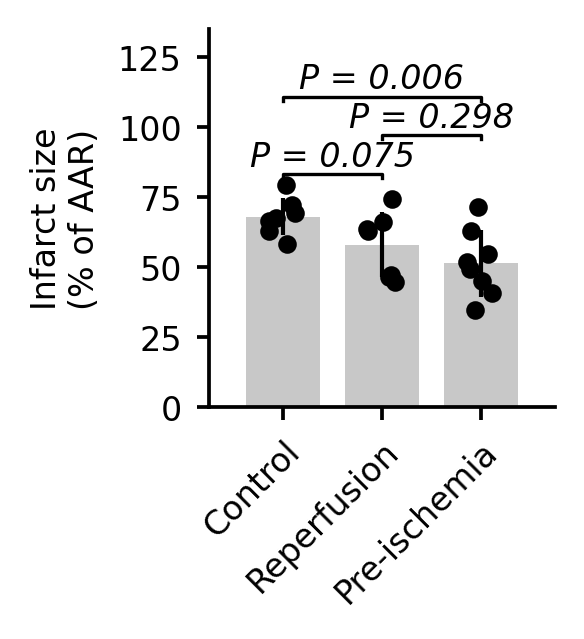

infarct_rhein | Rhein (Langendorff perfusion)
  Control       n=7  mean  68.1  SD  6.7  SEM  2.5
  Reperfusion   n=7  mean  58.0  SD 11.6  SEM  4.4
  Pre-ischemia  n=8  mean  51.4  SD 11.8  SEM  4.2
  Welch Control vs Reperfusion: P = 0.0754
  Welch Control vs Pre-ischemia: P = 0.0056
  Welch Reperfusion vs Pre-ischemia: P = 0.2981
  one-way ANOVA: F = 4.83, P = 0.0202



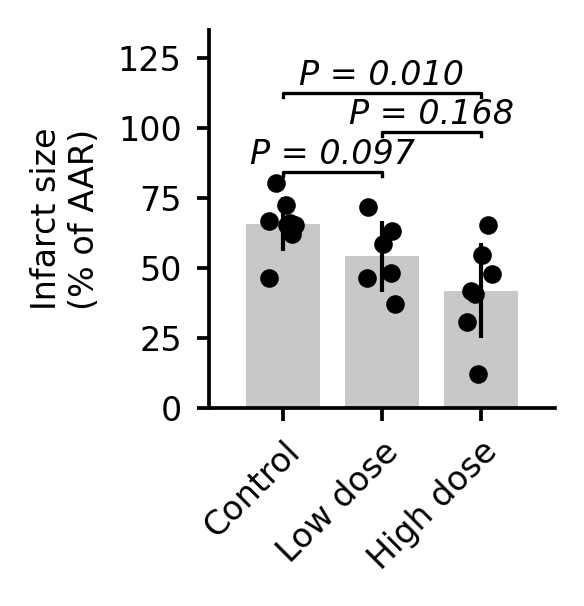

infarct_diacerein | Diacerein (oral gavage)
  Control       n=8  mean  65.5  SD  9.6  SEM  3.4
  Low dose      n=6  mean  54.1  SD 12.6  SEM  5.2
  High dose     n=7  mean  41.8  SD 17.1  SEM  6.5
  Welch Control vs Low dose: P = 0.0970
  Welch Control vs High dose: P = 0.0099
  Welch Low dose vs High dose: P = 0.1677
  one-way ANOVA: F = 5.88, P = 0.0108



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
#@title 5 · Draw both panels, save PDFs, print stats
PANELS = {
  'infarct_rhein':     ('Rhein (Langendorff perfusion)', ['Control', 'Reperfusion', 'Pre-ischemia']),
  'infarct_diacerein': ('Diacerein (oral gavage)',       ['Control', 'Low dose', 'High dose']),
}
for fname, (exp, groups) in PANELS.items():
    vals = [hearts[(hearts.exp == exp) & (hearts.group == g)].inf_pct.values for g in groups]
    p = {(a, b): stats.ttest_ind(vals[a], vals[b], equal_var=False).pvalue for a, b in combinations(range(len(groups)), 2)}
    F, pa = stats.f_oneway(*vals)
    fig, ax = fixed_panel()
    bar_dot_plot(groups, vals, 'Infarct size\n(% of AAR)', p, ax, ymax=Y_MAX)
    fig.savefig(f'{fname}.pdf'); fig.savefig(f'{fname}.png'); plt.show()   # no bbox_inches: keeps 4.6 × 5.0 cm
    print(fname, '|', exp)
    for g, v in zip(groups, vals): print(f'  {g:13s} n={len(v)}  mean {v.mean():5.1f}  SD {v.std(ddof=1):4.1f}  SEM {stats.sem(v):4.1f}')
    for (a, b), pv in p.items(): print(f'  Welch {groups[a]} vs {groups[b]}: P = {pv:.4f}')
    print(f'  one-way ANOVA: F = {F:.2f}, P = {pa:.4f}\n')
try:
    from google.colab import files
    for f in PANELS: files.download(f'{f}.pdf')
except ImportError:
    pass